# Actividad individual 5: Árboles de Clasificación y Regresión (CART)
### Caso GreenRide: transporte eléctrico compartido

**Objetivos del análisis:**
1. **Árbol de clasificación:** predecir si un usuario recomendaría el servicio (Sí / No).
2. **Árbol de regresión:** predecir el consumo energético semanal estimado (kWh) del usuario, reutilizando las mismas variables predictoras.

**Archivo de datos:** `greenride_dataset.csv`

## 1. Cargar librerías y datos

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, cross_val_predict
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_graphviz
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay,
                             accuracy_score, precision_score, recall_score, f1_score, mean_squared_error, mean_absolute_error, r2_score)

print("Versiones -> numpy:", np.__version__, "| pandas:", pd.__version__)
df = pd.read_csv('/content/greenride_dataset.csv')
df.head()

Versiones -> numpy: 2.5.3 | pandas: 2.3.3


,edad,ingresos_mensuales,km_semana,frecuencia_uso,satisfaccion_general,membresia_premium,dias_sin_uso,recomienda,consumo_kwh
0,34,12986,17.3,Baja,Baja,0,8,0,0.80
1,24,14384,23.0,Media,Media,0,3,0,1.12
2,38,18642,76.0,Alta,Media,1,1,0,3.93
3,40,16092,36.6,Media,Baja,0,3,0,1.40
4,18,7667,15.0,Media,Media,0,3,0,2.58


## 2. Exploración inicial de los datos
Revisamos dimensiones, tipos de variables y estadísticas descriptivas.

In [2]:
print("Dimensiones:", df.shape)
df.info()

Dimensiones: (1200, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   edad                  1200 non-null   int64  
 1   ingresos_mensuales    1200 non-null   int64  
 2   km_semana             1200 non-null   float64
 3   frecuencia_uso        1200 non-null   object 
 4   satisfaccion_general  1200 non-null   object 
 5   membresia_premium     1200 non-null   int64  
 6   dias_sin_uso          1200 non-null   int64  
 7   recomienda            1200 non-null   int64  
 8   consumo_kwh           1200 non-null   float64
dtypes: float64(2), int64(5), object(2)
memory usage: 84.5+ KB


In [3]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
edad,1200.0,NaN,NaN,NaN,31.968333,7.60014,18.0,27.0,32.0,37.0,57.0
ingresos_mensuales,1200.0,NaN,NaN,NaN,15205.574167,3857.054566,5000.0,12436.5,15144.0,17737.5,27838.0
km_semana,1200.0,NaN,NaN,NaN,38.747667,19.161812,5.0,24.3,37.6,53.825,90.0
frecuencia_uso,1200,3,Media,557,NaN,NaN,NaN,NaN,NaN,NaN,NaN
satisfaccion_general,1200,3,Baja,553,NaN,NaN,NaN,NaN,NaN,NaN,NaN
membresia_premium,1200.0,NaN,NaN,NaN,0.2775,0.447952,0.0,0.0,0.0,1.0,1.0
dias_sin_uso,1200.0,NaN,NaN,NaN,3.700833,2.747597,0.0,2.0,3.0,6.0,10.0
recomienda,1200.0,NaN,NaN,NaN,0.216667,0.412145,0.0,0.0,0.0,0.0,1.0
consumo_kwh,1200.0,NaN,NaN,NaN,1.767475,0.946883,0.8,0.8,1.56,2.43,4.67


Revisamos si existen valores faltantes y registros duplicados antes de decidir si es necesaria alguna limpieza.

In [4]:
print("Valores faltantes por columna:")
print(df.isnull().sum())
print("\nRegistros duplicados:", df.duplicated().sum())

Valores faltantes por columna:
edad                    0
ingresos_mensuales      0
km_semana               0
frecuencia_uso          0
satisfaccion_general    0
membresia_premium       0
dias_sin_uso            0
recomienda              0
consumo_kwh             0
dtype: int64

Registros duplicados: 0


Revisamos las categorías de las variables de texto y los valores únicos de las variables binarias.

In [5]:
for col in df.select_dtypes(include='object').columns:
    print(df[col].value_counts(), "\n")

print(df['membresia_premium'].value_counts(), "\n")
print(df['recomienda'].value_counts())

frecuencia_uso
Media    557
Alta     398
Baja     245
Name: count, dtype: int64 

satisfaccion_general
Baja     553
Media    463
Alta     184
Name: count, dtype: int64 

membresia_premium
0    867
1    333
Name: count, dtype: int64 

recomienda
0    940
1    260
Name: count, dtype: int64


Distribución de las dos variables objetivo.

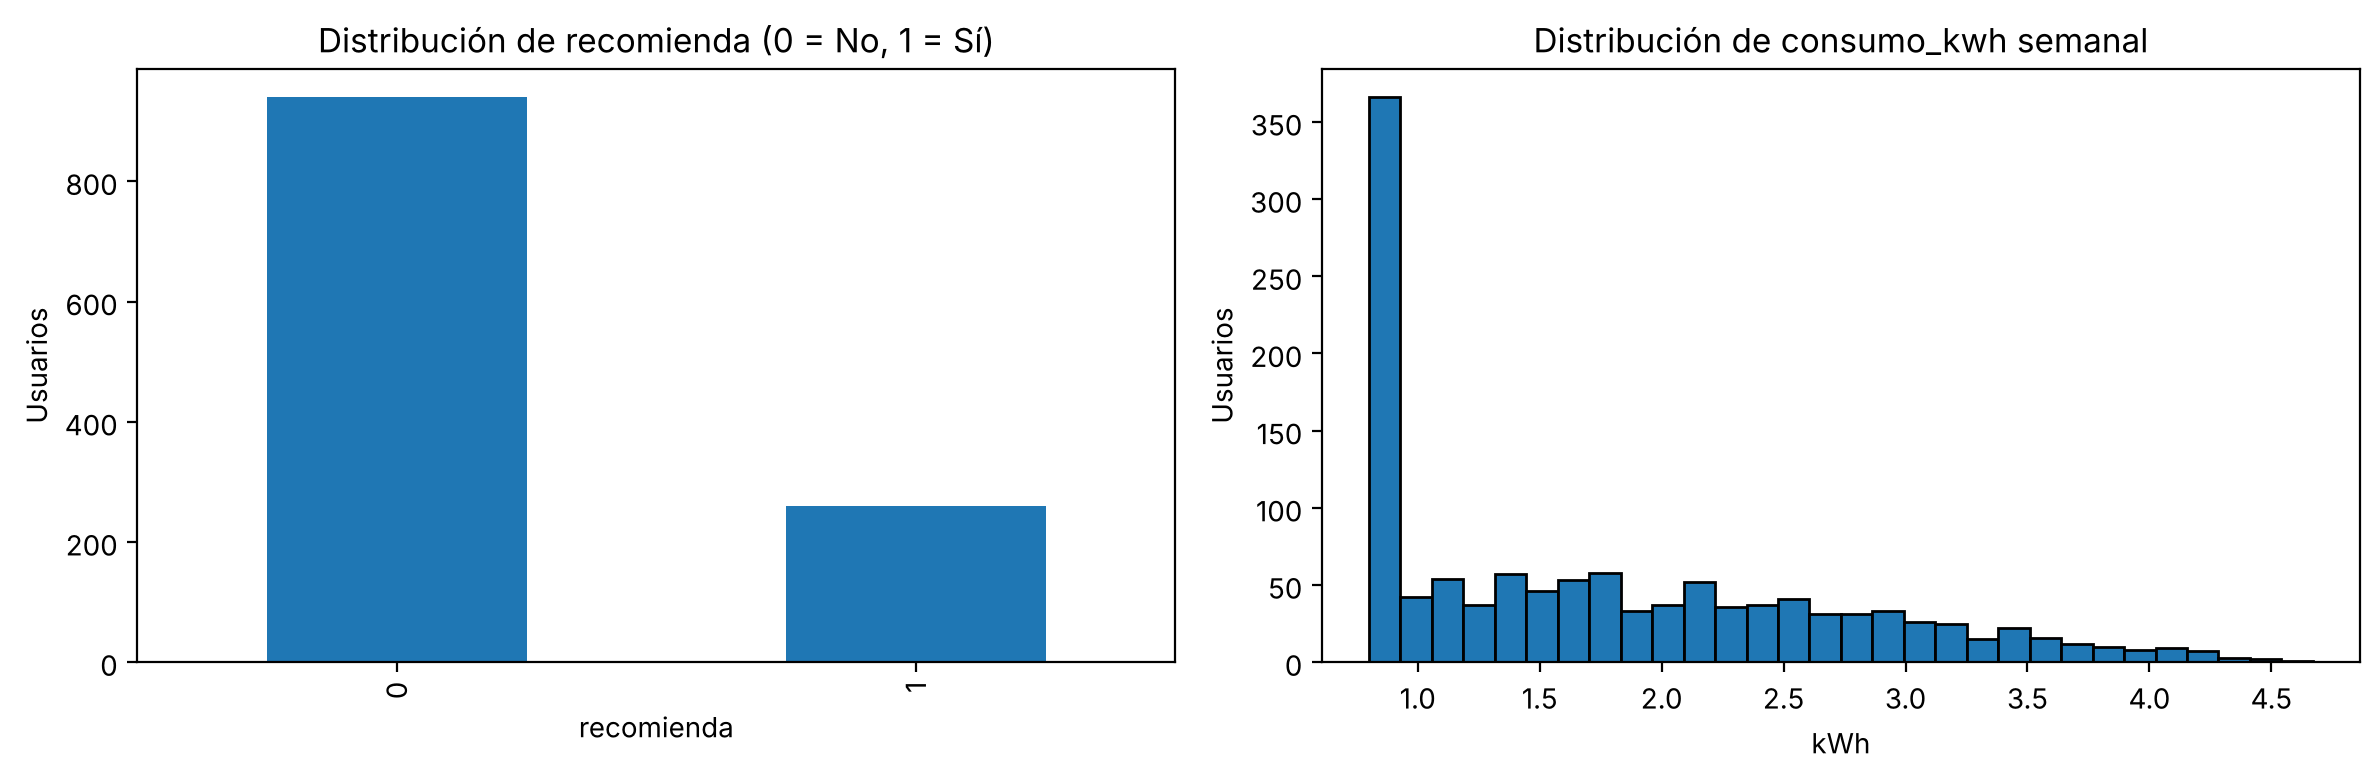

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df['recomienda'].value_counts().plot(kind='bar', ax=axes[0])
axes[0].set_title('Distribución de recomienda (0 = No, 1 = Sí)')
axes[0].set_xlabel('recomienda')
axes[0].set_ylabel('Usuarios')

axes[1].hist(df['consumo_kwh'], bins=30, edgecolor='black')
axes[1].set_title('Distribución de consumo_kwh semanal')
axes[1].set_xlabel('kWh')
axes[1].set_ylabel('Usuarios')

plt.tight_layout()
plt.show()

Relación de las variables con cada objetivo: tasa de recomendación por categoría y correlación de las numéricas con el consumo.

In [7]:
for col in ['frecuencia_uso', 'satisfaccion_general', 'membresia_premium']:
    print(df.groupby(col)['recomienda'].mean().round(3), "\n")

df.select_dtypes(exclude='object').corr()['consumo_kwh'].sort_values(ascending=False)

frecuencia_uso
Alta     0.397
Baja     0.049
Media    0.162
Name: recomienda, dtype: float64 

satisfaccion_general
Alta     0.772
Baja     0.056
Media    0.188
Name: recomienda, dtype: float64 

membresia_premium
0    0.088
1    0.553
Name: recomienda, dtype: float64 



consumo_kwh           1.000000
km_semana             0.827263
recomienda            0.285921
membresia_premium     0.130014
ingresos_mensuales    0.063202
edad                  0.013895
dias_sin_uso         -0.701603
Name: consumo_kwh, dtype: float64

## 3. Selección de variables

- **Variable objetivo – Modelo 1 (clasificación):** `recomienda` (0 = No, 1 = Sí).
- **Variable objetivo – Modelo 2 (regresión):** `consumo_kwh`.
- **Variables predictoras (las mismas para ambos modelos):** `edad`, `ingresos_mensuales`, `km_semana`, `frecuencia_uso`, `satisfaccion_general`, `membresia_premium`, `dias_sin_uso`.

Cada variable objetivo se excluye de los predictores del otro modelo: `consumo_kwh` no se conoce hasta que el usuario consume, y `recomienda` es una respuesta de encuesta, por lo que usarlas como predictores sería *data leakage*.

**Normalización:** no se aplica. Los árboles CART dividen los datos con umbrales (`km_semana <= 40`), por lo que la escala de las variables no cambia los cortes ni el resultado del modelo. Lo que sí se necesita es convertir las variables categóricas (`frecuencia_uso`, `satisfaccion_general`) a numéricas con *One-Hot Encoding*.

In [8]:
X = df.drop(columns=['recomienda', 'consumo_kwh'])
y_clf = df['recomienda']
y_reg = df['consumo_kwh']

cat_cols = X.select_dtypes(include='object').columns.tolist()
num_cols = X.select_dtypes(exclude='object').columns.tolist()

cat_cols, num_cols

(['frecuencia_uso', 'satisfaccion_general'],
 ['edad',
  'ingresos_mensuales',
  'km_semana',
  'membresia_premium',
  'dias_sin_uso'])

In [9]:
preprocess = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
        ('num', 'passthrough', num_cols)
    ]
)

---
# MODELO 1: Árbol de Clasificación
## 4. División en entrenamiento y prueba
Se usa `stratify` porque las clases están desbalanceadas, para conservar la misma proporción de recomendadores en ambos conjuntos.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y_clf, test_size=0.25, random_state=42, stratify=y_clf)

X_train.shape, X_test.shape

((900, 7), (300, 7))

## 5. Pipeline + búsqueda de hiperparámetros
Se usa `f1` como métrica de búsqueda, porque con clases desbalanceadas la *accuracy* puede ser engañosa.

In [11]:
pipe_clf = Pipeline(steps=[('prep', preprocess),
                           ('model', DecisionTreeClassifier(random_state=42))])

param_grid = {
    'model__criterion': ['gini', 'entropy'],
    'model__max_depth': [3, 4, 5, 6, None],
    'model__min_samples_split': [2, 10, 20],
    'model__min_samples_leaf': [1, 5, 10]
}

grid_clf = GridSearchCV(pipe_clf, param_grid, cv=5, scoring='f1', n_jobs=-1)
grid_clf.fit(X_train, y_train)

i = grid_clf.best_index_
print(f"F1 CV del mejor modelo: {grid_clf.cv_results_['mean_test_score'][i]:.3f} ± {grid_clf.cv_results_['std_test_score'][i]:.3f}")
print("F1 por partición:", [round(float(grid_clf.cv_results_[f'split{k}_test_score'][i]), 3) for k in range(5)])

grid_clf.best_params_, grid_clf.best_score_

F1 CV del mejor modelo: 0.725 ± 0.052
F1 por partición: [0.756, 0.734, 0.775, 0.737, 0.625]


({'model__criterion': 'gini',
  'model__max_depth': 3,
  'model__min_samples_leaf': 1,
  'model__min_samples_split': 2},
 np.float64(0.7254233762857283))

Estructura del mejor modelo: preprocesamiento (One-Hot Encoding + variables numéricas sin cambios) y árbol de clasificación.

In [12]:
best_clf = grid_clf.best_estimator_
best_clf

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['edad','ingresos_mensuales','km_semana',...,'satisfaccion_general', 'membresia_premium','dias_sin_uso']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

## 6. Evaluación en el conjunto de prueba

               precision    recall  f1-score   support

No recomienda      0.912     0.923     0.918       235
   Recomienda      0.710     0.677     0.693        65

     accuracy                          0.870       300
    macro avg      0.811     0.800     0.805       300
 weighted avg      0.868     0.870     0.869       300



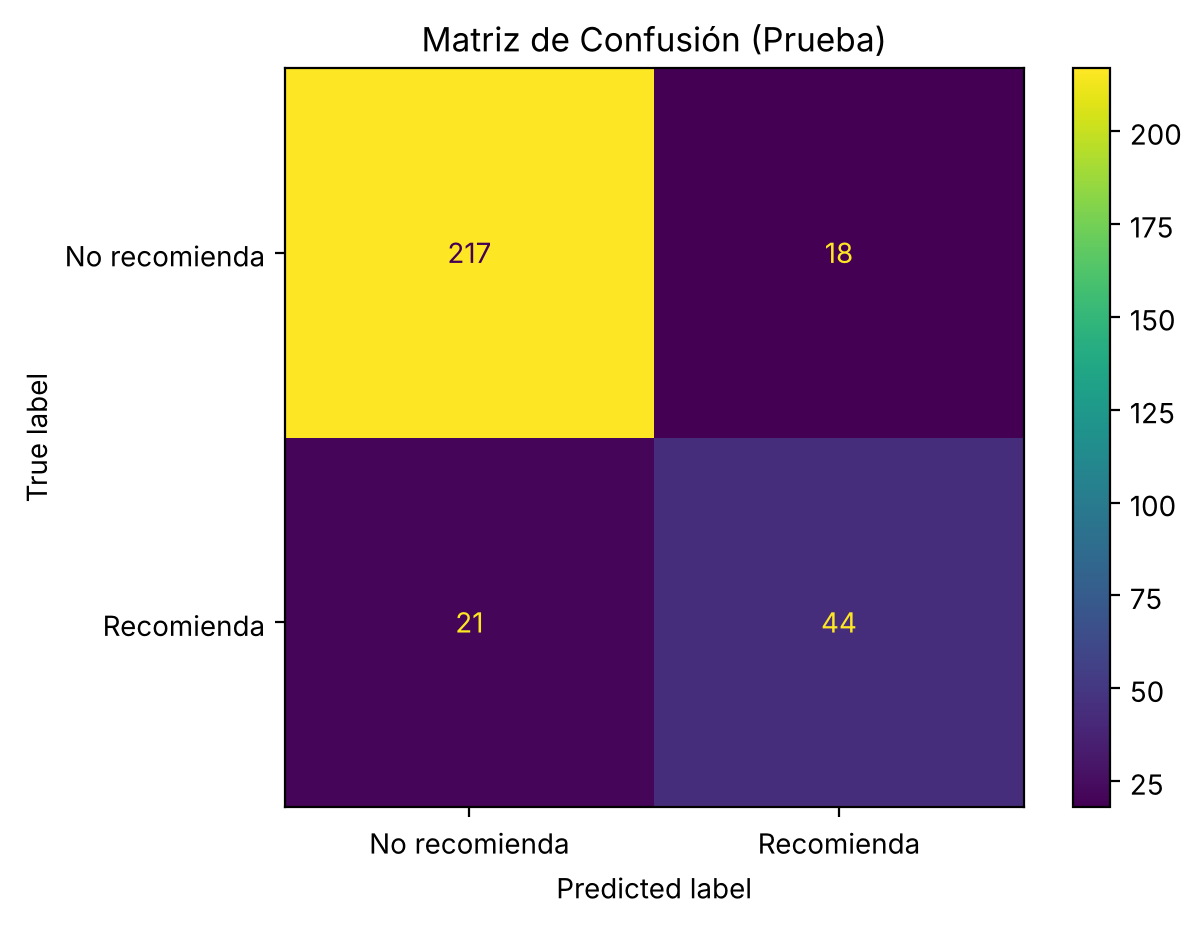

ROC AUC: 0.831


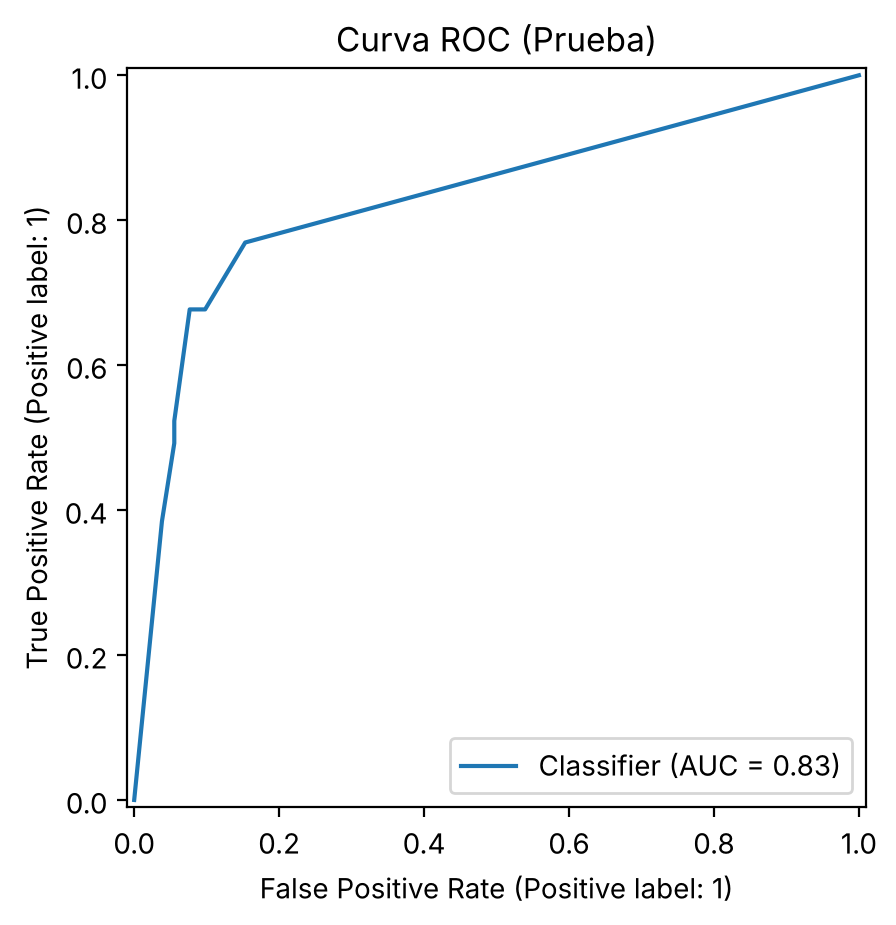

In [13]:
y_pred = best_clf.predict(X_test)
y_proba = best_clf.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=['No recomienda', 'Recomienda'], digits=3))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['No recomienda', 'Recomienda'])
plt.title("Matriz de Confusión (Prueba)")
plt.show()

auc = roc_auc_score(y_test, y_proba)
print("ROC AUC:", round(auc, 3))

RocCurveDisplay.from_predictions(y_test, y_proba)
plt.title("Curva ROC (Prueba)")
plt.show()

## 7. Interpretación del árbol (estructura y reglas)

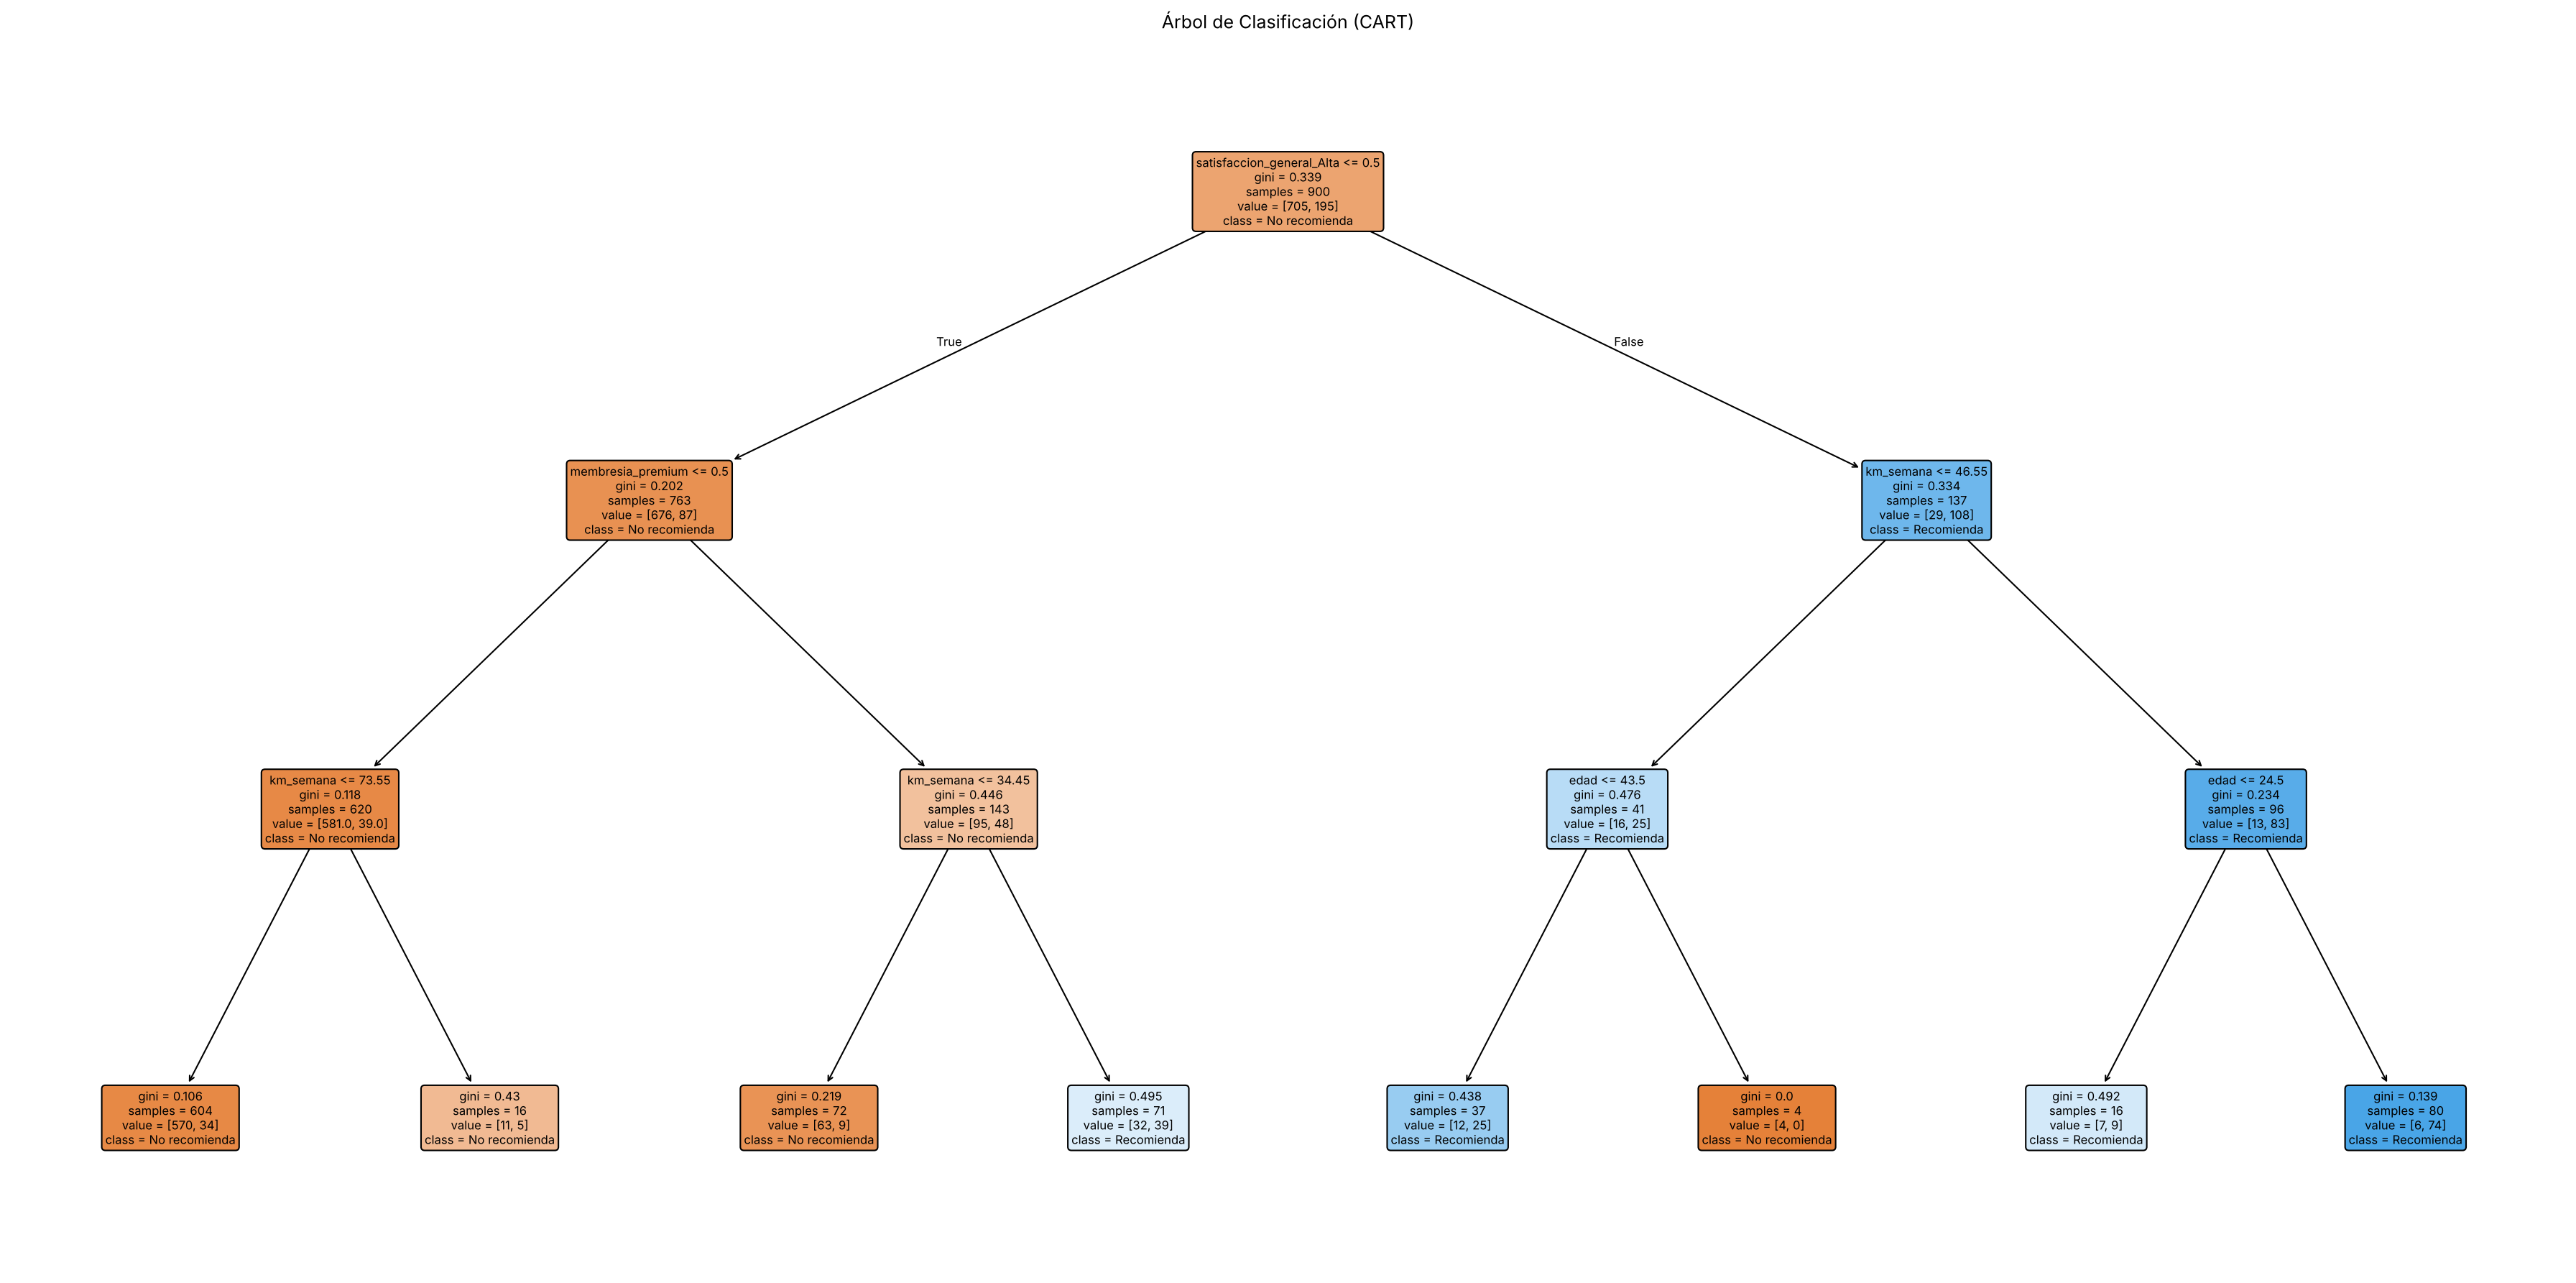

In [14]:
clf = best_clf.named_steps['model']

ohe = best_clf.named_steps['prep'].named_transformers_['cat']
feature_names = ohe.get_feature_names_out(cat_cols).tolist() + num_cols

plt.figure(figsize=(24, 12), dpi=150)
plot_tree(clf, feature_names=feature_names, class_names=['No recomienda', 'Recomienda'],
          filled=True, rounded=True, fontsize=8)
plt.title("Árbol de Clasificación (CART)")
plt.tight_layout()
plt.show()

### Reglas de decisión principales
El **nodo raíz es `satisfaccion_general_Alta`**, la variable que más reduce la impureza (Gini).

**Usuarios con satisfacción Alta (rama derecha, 79 % recomienda):**
- **Regla 1:** satisfacción Alta, `km_semana` > 46.6 y edad > 24.5 → **Recomienda** (74 de 80 usuarios, 93 %). Es el **perfil promotor**: usuario satisfecho, que usa mucho el servicio y es adulto.
- **Regla 2:** satisfacción Alta, `km_semana` ≤ 46.6 y edad ≤ 43.5 → **Recomienda** (68 %).
- Los mayores de 43.5 años con poco recorrido son muy pocos (4 usuarios) y no recomiendan.

**Usuarios con satisfacción Media o Baja (rama izquierda, solo 11 % recomienda):**
- **Regla 3:** sin membresía premium y `km_semana` ≤ 73.6 → **No recomienda** (570 de 604, 94 %). Es el grupo más grande de la base: usuarios básicos y poco satisfechos.
- **Regla 4:** con membresía premium y `km_semana` > 34.5 → **Recomienda** (55 %). La membresía premium junto con un uso intenso logra que incluso usuarios no tan satisfechos recomienden.

## 8. Importancia de variables (clasificación)

satisfaccion_general_Alta     0.711916
km_semana                     0.125703
membresia_premium             0.116544
edad                          0.045836
frecuencia_uso_Media          0.000000
frecuencia_uso_Alta           0.000000
frecuencia_uso_Baja           0.000000
satisfaccion_general_Media    0.000000
satisfaccion_general_Baja     0.000000
ingresos_mensuales            0.000000
dias_sin_uso                  0.000000
dtype: float64


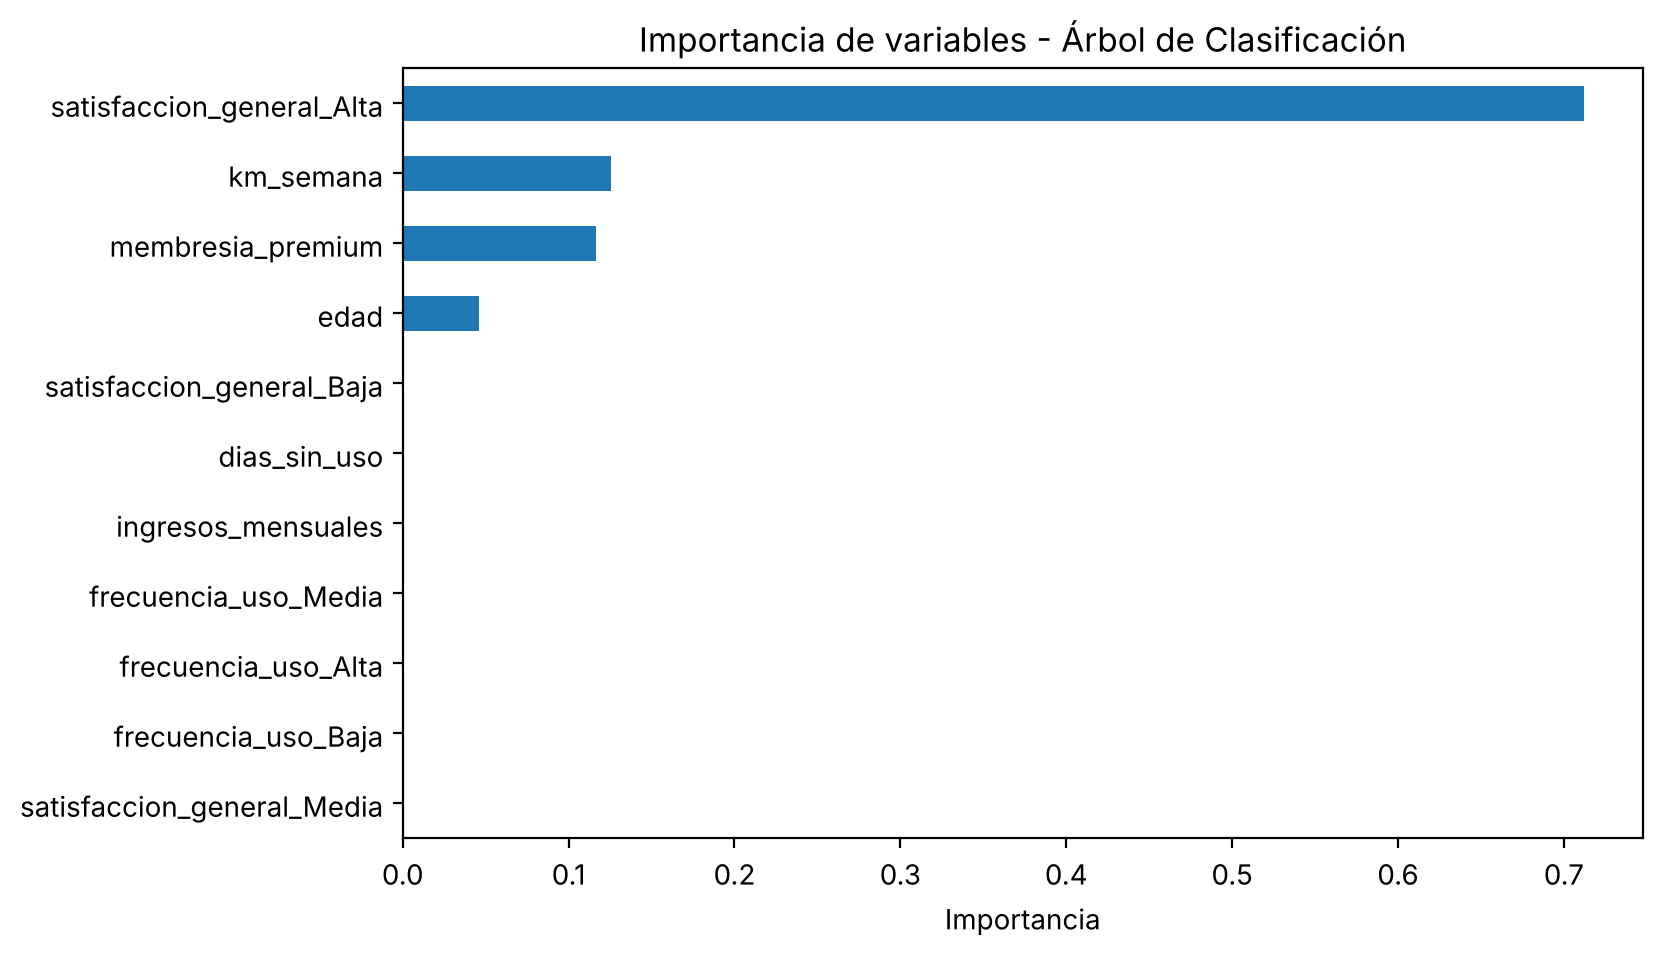

In [15]:
imp_clf = pd.Series(clf.feature_importances_, index=feature_names).sort_values(ascending=False)
print(imp_clf)

imp_clf.sort_values().plot(kind='barh', figsize=(8, 5))
plt.title('Importancia de variables - Árbol de Clasificación')
plt.xlabel('Importancia')
plt.show()

### Interpretación de la importancia de variables
- **`satisfaccion_general_Alta` (71 %)** domina la decisión: tener satisfacción alta es el principal factor para recomendar.
- **`km_semana` (13 %)** y **`membresia_premium` (12 %)** completan el perfil: quien usa más el servicio y tiene membresía premium tiende a recomendarlo.
- **`edad` (5 %)** solo matiza algunos casos.
- `ingresos_mensuales`, `dias_sin_uso` y `frecuencia_uso` **no participan** en el árbol final. Su información ya está cubierta por las variables anteriores (por ejemplo, `km_semana` resume la intensidad de uso).
- La importancia indica asociación, **no causalidad**.

## 9. Sobreajuste y generalización (clasificación)
Comparamos el F1 en entrenamiento contra el F1 de validación cruzada al aumentar la profundidad del árbol. El conjunto de prueba no se usa aquí; se reserva para la evaluación final.

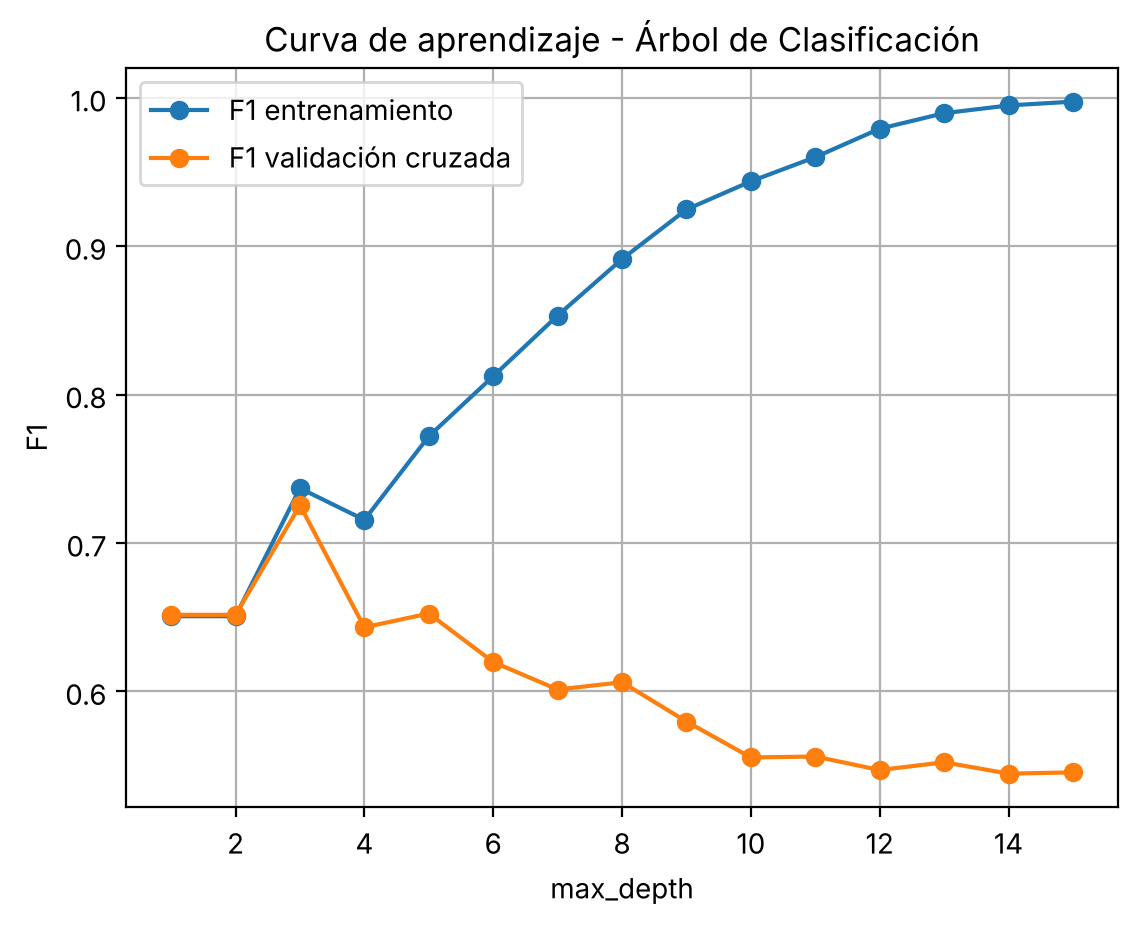

Profundidad óptima (F1 CV): 3 | F1 CV: 0.725
Modelo final -> Accuracy entrenamiento: 0.883 | Accuracy prueba: 0.87
Modelo final -> F1 entrenamiento: 0.737 | F1 prueba: 0.693


In [16]:
train_f1, cv_f1 = [], []
depths = range(1, 16)

for d in depths:
    m = Pipeline([('prep', preprocess),
                  ('model', DecisionTreeClassifier(max_depth=d, random_state=42))])
    cv_f1.append(cross_val_score(m, X_train, y_train, cv=5, scoring='f1').mean())
    m.fit(X_train, y_train)
    train_f1.append(f1_score(y_train, m.predict(X_train)))

plt.plot(depths, train_f1, label='F1 entrenamiento', marker='o')
plt.plot(depths, cv_f1, label='F1 validación cruzada', marker='o')
plt.xlabel('max_depth')
plt.ylabel('F1')
plt.legend()
plt.grid(True)
plt.title('Curva de aprendizaje - Árbol de Clasificación')
plt.show()

print("Profundidad óptima (F1 CV):", depths[int(np.argmax(cv_f1))], "| F1 CV:", round(max(cv_f1), 3))

print("Modelo final -> Accuracy entrenamiento:", round(accuracy_score(y_train, best_clf.predict(X_train)), 3),
      "| Accuracy prueba:", round(accuracy_score(y_test, y_pred), 3))
print("Modelo final -> F1 entrenamiento:", round(f1_score(y_train, best_clf.predict(X_train)), 3),
      "| F1 prueba:", round(f1_score(y_test, y_pred), 3))

### Interpretación del sobreajuste
- **F1 en entrenamiento:** sube de forma continua con la profundidad y llega a 0.997 con `max_depth` = 15. El árbol termina memorizando los datos.
- **F1 en validación cruzada:** alcanza su máximo en **`max_depth` = 3 (0.725)** y después baja hasta 0.545. Es la señal clásica de **sobreajuste**.
- La profundidad se eligió solo con validación cruzada. El conjunto de prueba se usa únicamente para la evaluación final.
- **Modelo final (`max_depth` = 3):** la diferencia entre entrenamiento y prueba es pequeña (accuracy 0.883 vs 0.870; F1 0.737 vs 0.693), así que **generaliza bien**.

## 10. Corrección del desbalance de clases
Solo el 21.7 % de los usuarios recomienda el servicio, y el modelo anterior detecta a 68 % de ellos (recall). Entrenamos una segunda versión con `class_weight='balanced'`, que da más peso a los errores en la clase minoritaria, con la misma búsqueda de hiperparámetros.

In [17]:
pipe_bal = Pipeline(steps=[('prep', preprocess),
                           ('model', DecisionTreeClassifier(class_weight='balanced', random_state=42))])

grid_bal = GridSearchCV(pipe_bal, param_grid, cv=5, scoring='f1', n_jobs=-1)
grid_bal.fit(X_train, y_train)

i = grid_bal.best_index_
print(f"F1 CV del mejor modelo: {grid_bal.cv_results_['mean_test_score'][i]:.3f} ± {grid_bal.cv_results_['std_test_score'][i]:.3f}")
print("F1 por partición:", [round(float(grid_bal.cv_results_[f'split{k}_test_score'][i]), 3) for k in range(5)])

grid_bal.best_params_, grid_bal.best_score_

F1 CV del mejor modelo: 0.704 ± 0.044
F1 por partición: [0.703, 0.705, 0.756, 0.729, 0.625]


({'model__criterion': 'entropy',
  'model__max_depth': 3,
  'model__min_samples_leaf': 1,
  'model__min_samples_split': 2},
 np.float64(0.7036702967047301))

               precision    recall  f1-score   support

No recomienda      0.921     0.889     0.905       235
   Recomienda      0.644     0.723     0.681        65

     accuracy                          0.853       300
    macro avg      0.782     0.806     0.793       300
 weighted avg      0.861     0.853     0.856       300



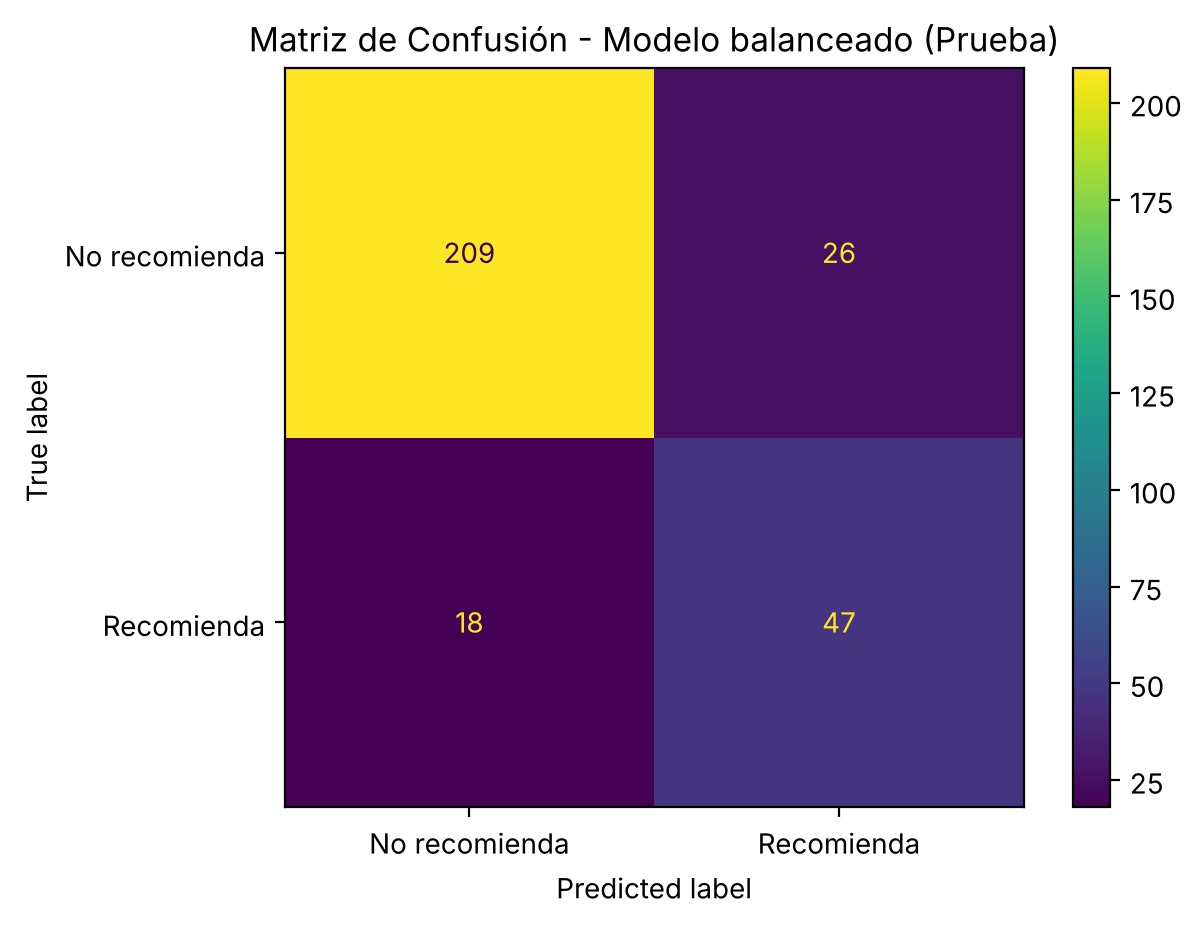

In [18]:
best_bal = grid_bal.best_estimator_
y_pred_bal = best_bal.predict(X_test)
y_proba_bal = best_bal.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_bal, target_names=['No recomienda', 'Recomienda'], digits=3))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_bal, display_labels=['No recomienda', 'Recomienda'])
plt.title("Matriz de Confusión - Modelo balanceado (Prueba)")
plt.show()

Comparamos ambos modelos con las mismas métricas sobre el conjunto de prueba.

                        Original  Balanceado
Accuracy                   0.870       0.853
Precisión (Recomienda)     0.710       0.644
Recall (Recomienda)        0.677       0.723
F1 (Recomienda)            0.693       0.681
ROC AUC                    0.831       0.832


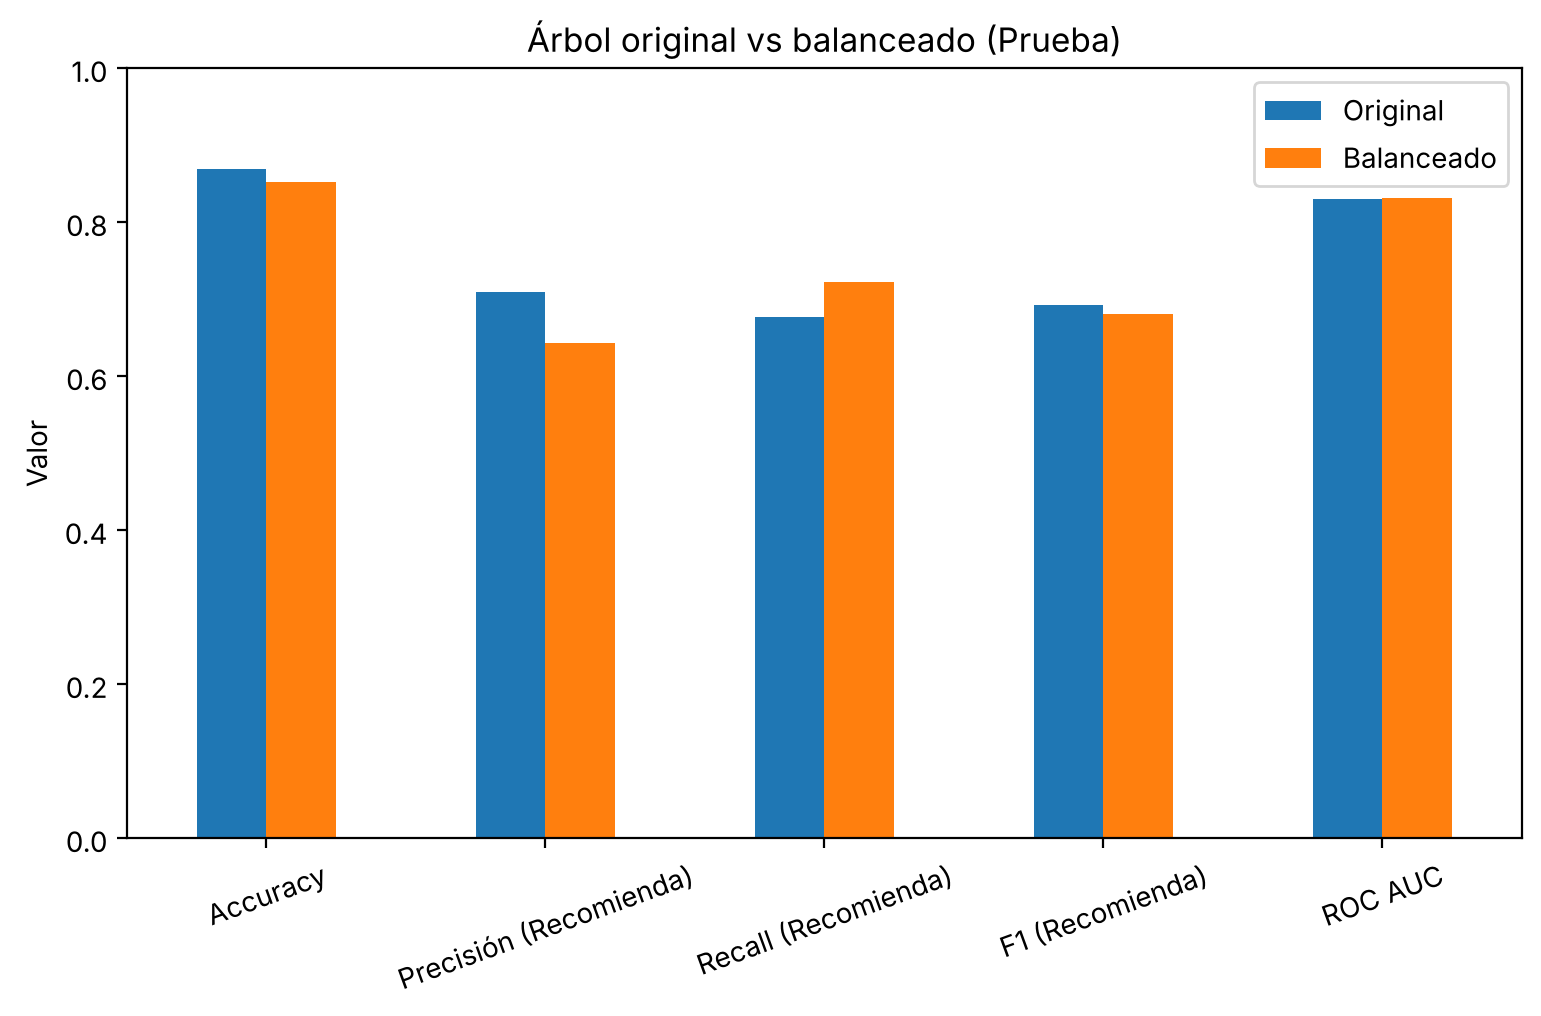

In [19]:
comparacion = pd.DataFrame({
    'Original': [accuracy_score(y_test, y_pred), precision_score(y_test, y_pred),
                 recall_score(y_test, y_pred), f1_score(y_test, y_pred), roc_auc_score(y_test, y_proba)],
    'Balanceado': [accuracy_score(y_test, y_pred_bal), precision_score(y_test, y_pred_bal),
                   recall_score(y_test, y_pred_bal), f1_score(y_test, y_pred_bal), roc_auc_score(y_test, y_proba_bal)]
}, index=['Accuracy', 'Precisión (Recomienda)', 'Recall (Recomienda)', 'F1 (Recomienda)', 'ROC AUC']).round(3)
print(comparacion)

comparacion.plot(kind='bar', figsize=(9, 5))
plt.title('Árbol original vs balanceado (Prueba)')
plt.ylabel('Valor')
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.show()

Revisamos si la mejora en recall se mantiene en las 5 particiones de validación cruzada (solo datos de entrenamiento), y no solo en el conjunto de prueba.

In [20]:
for nombre, modelo in [('Original', best_clf), ('Balanceado', best_bal)]:
    rec = cross_val_score(modelo, X_train, y_train, cv=5, scoring='recall')
    print(f"{nombre} -> Recall CV: {rec.mean():.3f} ± {rec.std():.3f} | por partición: {rec.round(3).tolist()}")

Original -> Recall CV: 0.738 ± 0.057 | por partición: [0.795, 0.744, 0.795, 0.718, 0.641]
Balanceado -> Recall CV: 0.769 ± 0.065 | por partición: [0.821, 0.795, 0.795, 0.795, 0.641]


**Interpretación:** el recall promedio en validación cruzada sube de 0.738 a 0.769 con el modelo balanceado. Mejora en 3 de las 5 particiones y en las otras 2 queda igual, así que la mejora observada en prueba no es casualidad de una sola partición. Que las métricas sean consistentes entre particiones (desviación de ±0.05 a ±0.06) indica que la estimación es estable. Eso no significa que el modelo detecte bien la clase minoritaria: ambos modelos siguen sin detectar entre 23 % y 26 % de los recomendadores.

## 11. Selección del umbral de clasificación
El árbol clasifica como "Recomienda" cuando la probabilidad es mayor o igual a 0.5. Probamos otros umbrales con el modelo original.
- **Selección:** con probabilidades de validación cruzada (`cross_val_predict`) calculadas solo con los datos de entrenamiento.
- **Evaluación:** el umbral elegido se aplica una sola vez al conjunto de prueba.

        Precisión  Recall     F1
Umbral                          
0.2         0.679   0.769  0.721
0.3         0.679   0.769  0.721
0.4         0.712   0.749  0.730
0.5         0.716   0.749  0.732
0.6         0.809   0.477  0.600
0.7         0.859   0.405  0.551


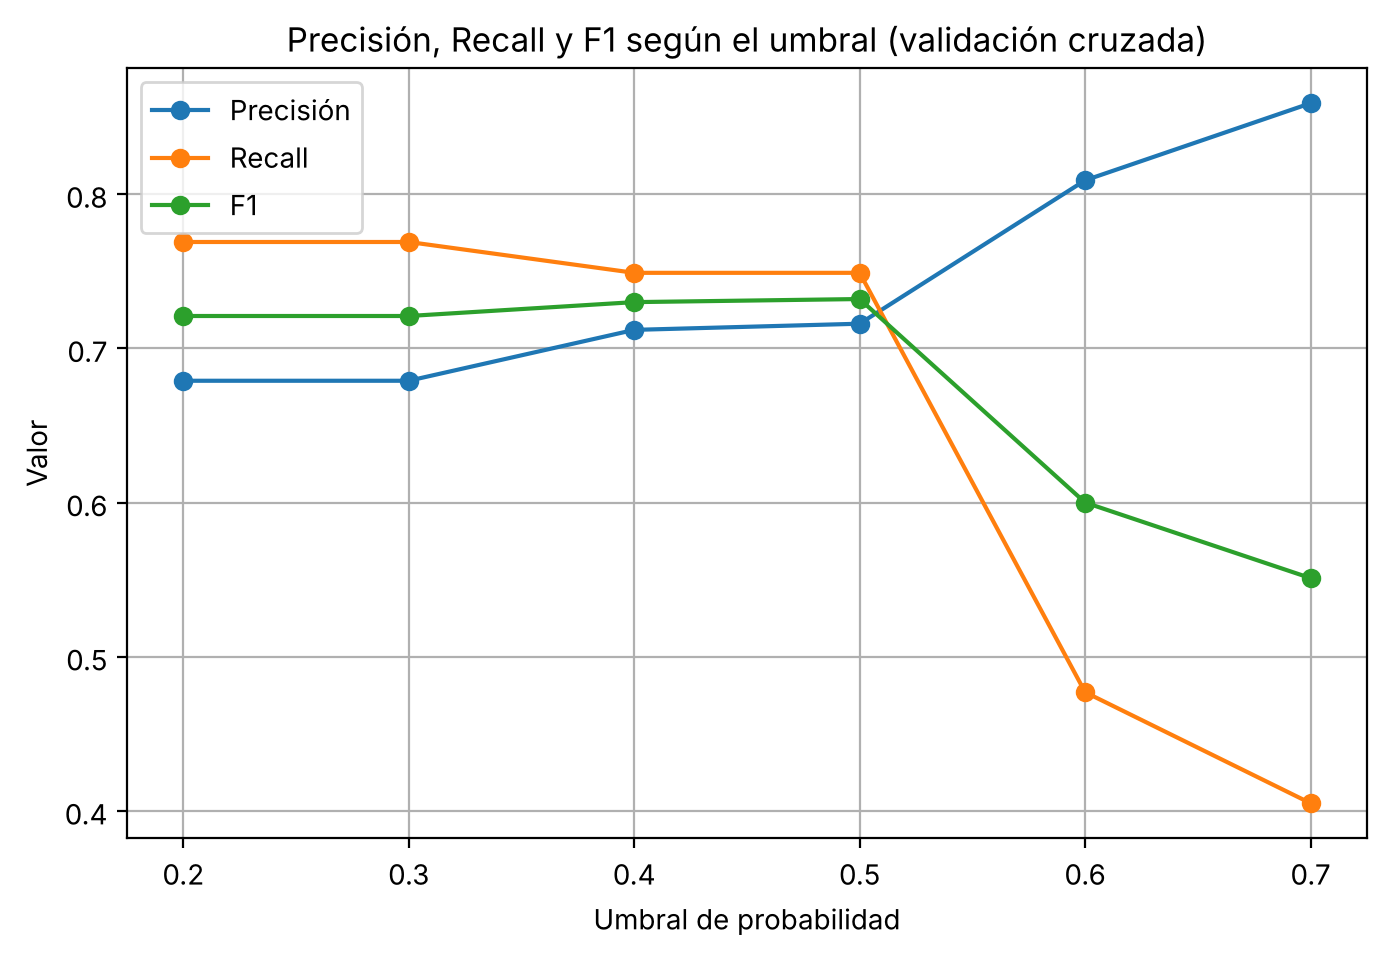

Umbral con mayor F1 en validación cruzada: 0.5


In [21]:
proba_cv = cross_val_predict(best_clf, X_train, y_train, cv=5, method='predict_proba')[:, 1]

umbrales = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
tabla_umbral = pd.DataFrame({
    'Precisión': [precision_score(y_train, proba_cv >= u) for u in umbrales],
    'Recall': [recall_score(y_train, proba_cv >= u) for u in umbrales],
    'F1': [f1_score(y_train, proba_cv >= u) for u in umbrales]
}, index=umbrales).round(3)
tabla_umbral.index.name = 'Umbral'
print(tabla_umbral)

tabla_umbral.plot(marker='o', figsize=(8, 5))
plt.title('Precisión, Recall y F1 según el umbral (validación cruzada)')
plt.xlabel('Umbral de probabilidad')
plt.ylabel('Valor')
plt.grid(True)
plt.show()

umbral_opt = tabla_umbral['F1'].idxmax()
print("Umbral con mayor F1 en validación cruzada:", umbral_opt)

In [22]:
for u in [umbral_opt, 0.3]:
    y_pred_umbral = (y_proba >= u).astype(int)
    print(f"Umbral {u} -> evaluación en prueba")
    print(classification_report(y_test, y_pred_umbral, target_names=['No recomienda', 'Recomienda'], digits=3))

Umbral 0.5 -> evaluación en prueba
               precision    recall  f1-score   support

No recomienda      0.912     0.923     0.918       235
   Recomienda      0.710     0.677     0.693        65

     accuracy                          0.870       300
    macro avg      0.811     0.800     0.805       300
 weighted avg      0.868     0.870     0.869       300

Umbral 0.3 -> evaluación en prueba
               precision    recall  f1-score   support

No recomienda      0.910     0.902     0.906       235
   Recomienda      0.657     0.677     0.667        65

     accuracy                          0.853       300
    macro avg      0.783     0.790     0.786       300
 weighted avg      0.855     0.853     0.854       300



---
# MODELO 2: Árbol de Regresión
## 12. División en entrenamiento y prueba
Se usan las mismas variables predictoras `X`, ahora con `consumo_kwh` como objetivo.

In [23]:
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X, y_reg, test_size=0.25, random_state=42)

Xr_train.shape, Xr_test.shape

((900, 7), (300, 7))

## 13. Pipeline + búsqueda de hiperparámetros

In [24]:
pipe_reg = Pipeline(steps=[('prep', preprocess),
                           ('model', DecisionTreeRegressor(random_state=42))])

grid_reg = GridSearchCV(pipe_reg,
                        {'model__max_depth': [3, 4, 5, 6, 8, None],
                         'model__min_samples_leaf': [1, 5, 10]},
                        cv=5, scoring='r2', n_jobs=-1)
grid_reg.fit(Xr_train, yr_train)

i = grid_reg.best_index_
print(f"R² CV del mejor modelo: {grid_reg.cv_results_['mean_test_score'][i]:.3f} ± {grid_reg.cv_results_['std_test_score'][i]:.3f}")
print("R² por partición:", [round(float(grid_reg.cv_results_[f'split{k}_test_score'][i]), 3) for k in range(5)])

grid_reg.best_params_, grid_reg.best_score_

R² CV del mejor modelo: 0.701 ± 0.029
R² por partición: [0.698, 0.733, 0.735, 0.668, 0.669]


({'model__max_depth': 3, 'model__min_samples_leaf': 5},
 np.float64(0.7005667387844707))

Estructura del mejor modelo: el mismo preprocesamiento, ahora con el árbol de regresión.

In [25]:
best_reg = grid_reg.best_estimator_
best_reg

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['edad','ingresos_mensuales','km_semana',...,'satisfaccion_general', 'membresia_premium','dias_sin_uso']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through.

## 14. Evaluación en el conjunto de prueba

MSE: 0.2633 | RMSE: 0.5131 kWh | MAE: 0.3819 kWh | R²: 0.6984
Referencia (predecir siempre el promedio de entrenamiento) -> MAE: 0.7885 kWh | R²: -0.0002


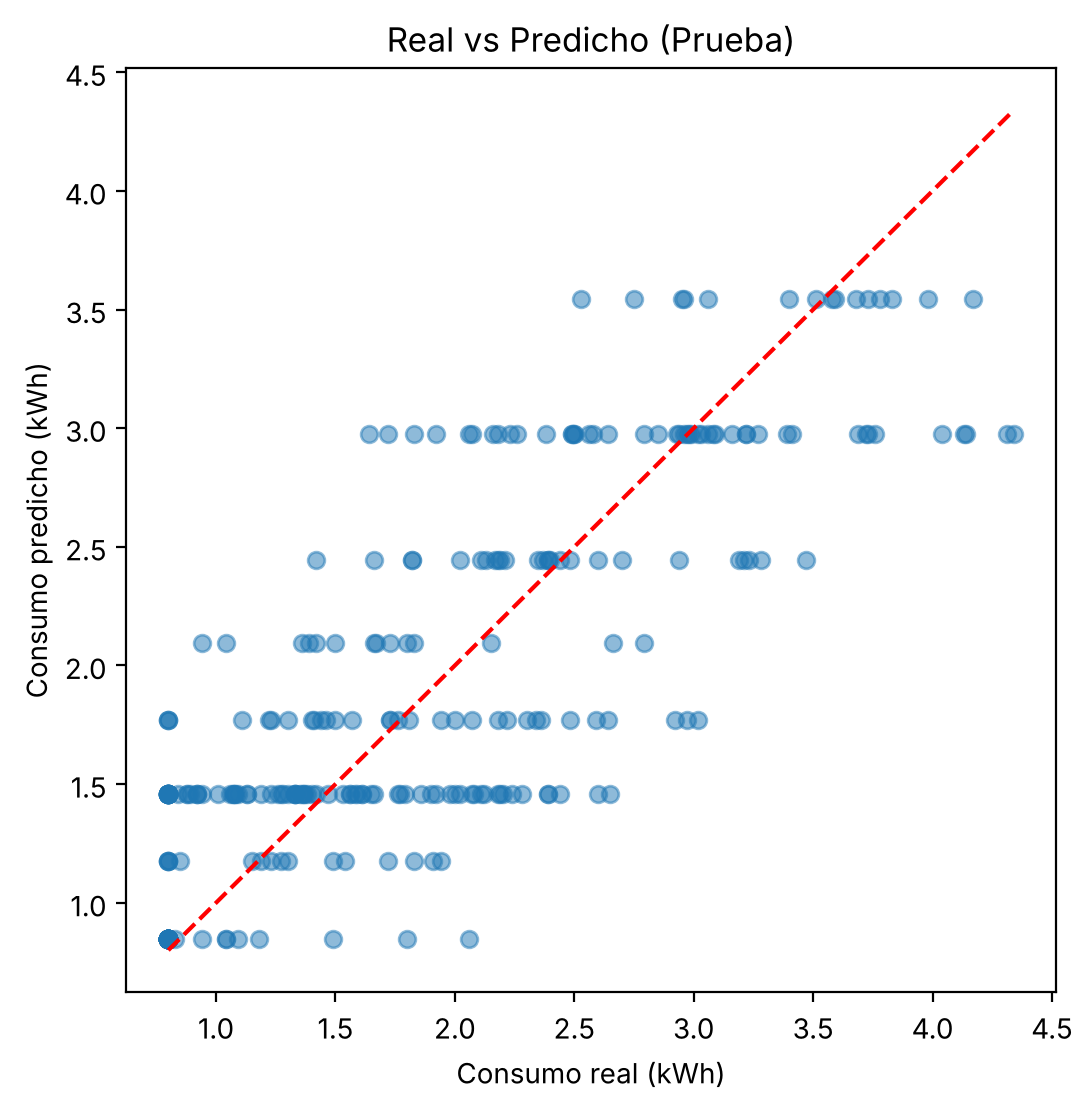

In [26]:
yr_pred = best_reg.predict(Xr_test)

mse = mean_squared_error(yr_test, yr_pred)
mae = mean_absolute_error(yr_test, yr_pred)
r2 = r2_score(yr_test, yr_pred)
print(f"MSE: {mse:.4f} | RMSE: {np.sqrt(mse):.4f} kWh | MAE: {mae:.4f} kWh | R²: {r2:.4f}")

y_base = np.full(len(yr_test), yr_train.mean())
print(f"Referencia (predecir siempre el promedio de entrenamiento) -> MAE: {mean_absolute_error(yr_test, y_base):.4f} kWh | R²: {r2_score(yr_test, y_base):.4f}")

plt.figure(figsize=(6, 6))
plt.scatter(yr_test, yr_pred, alpha=0.5)
plt.plot([yr_test.min(), yr_test.max()], [yr_test.min(), yr_test.max()], 'r--')
plt.xlabel('Consumo real (kWh)')
plt.ylabel('Consumo predicho (kWh)')
plt.title('Real vs Predicho (Prueba)')
plt.show()

## 15. Interpretación del árbol de regresión

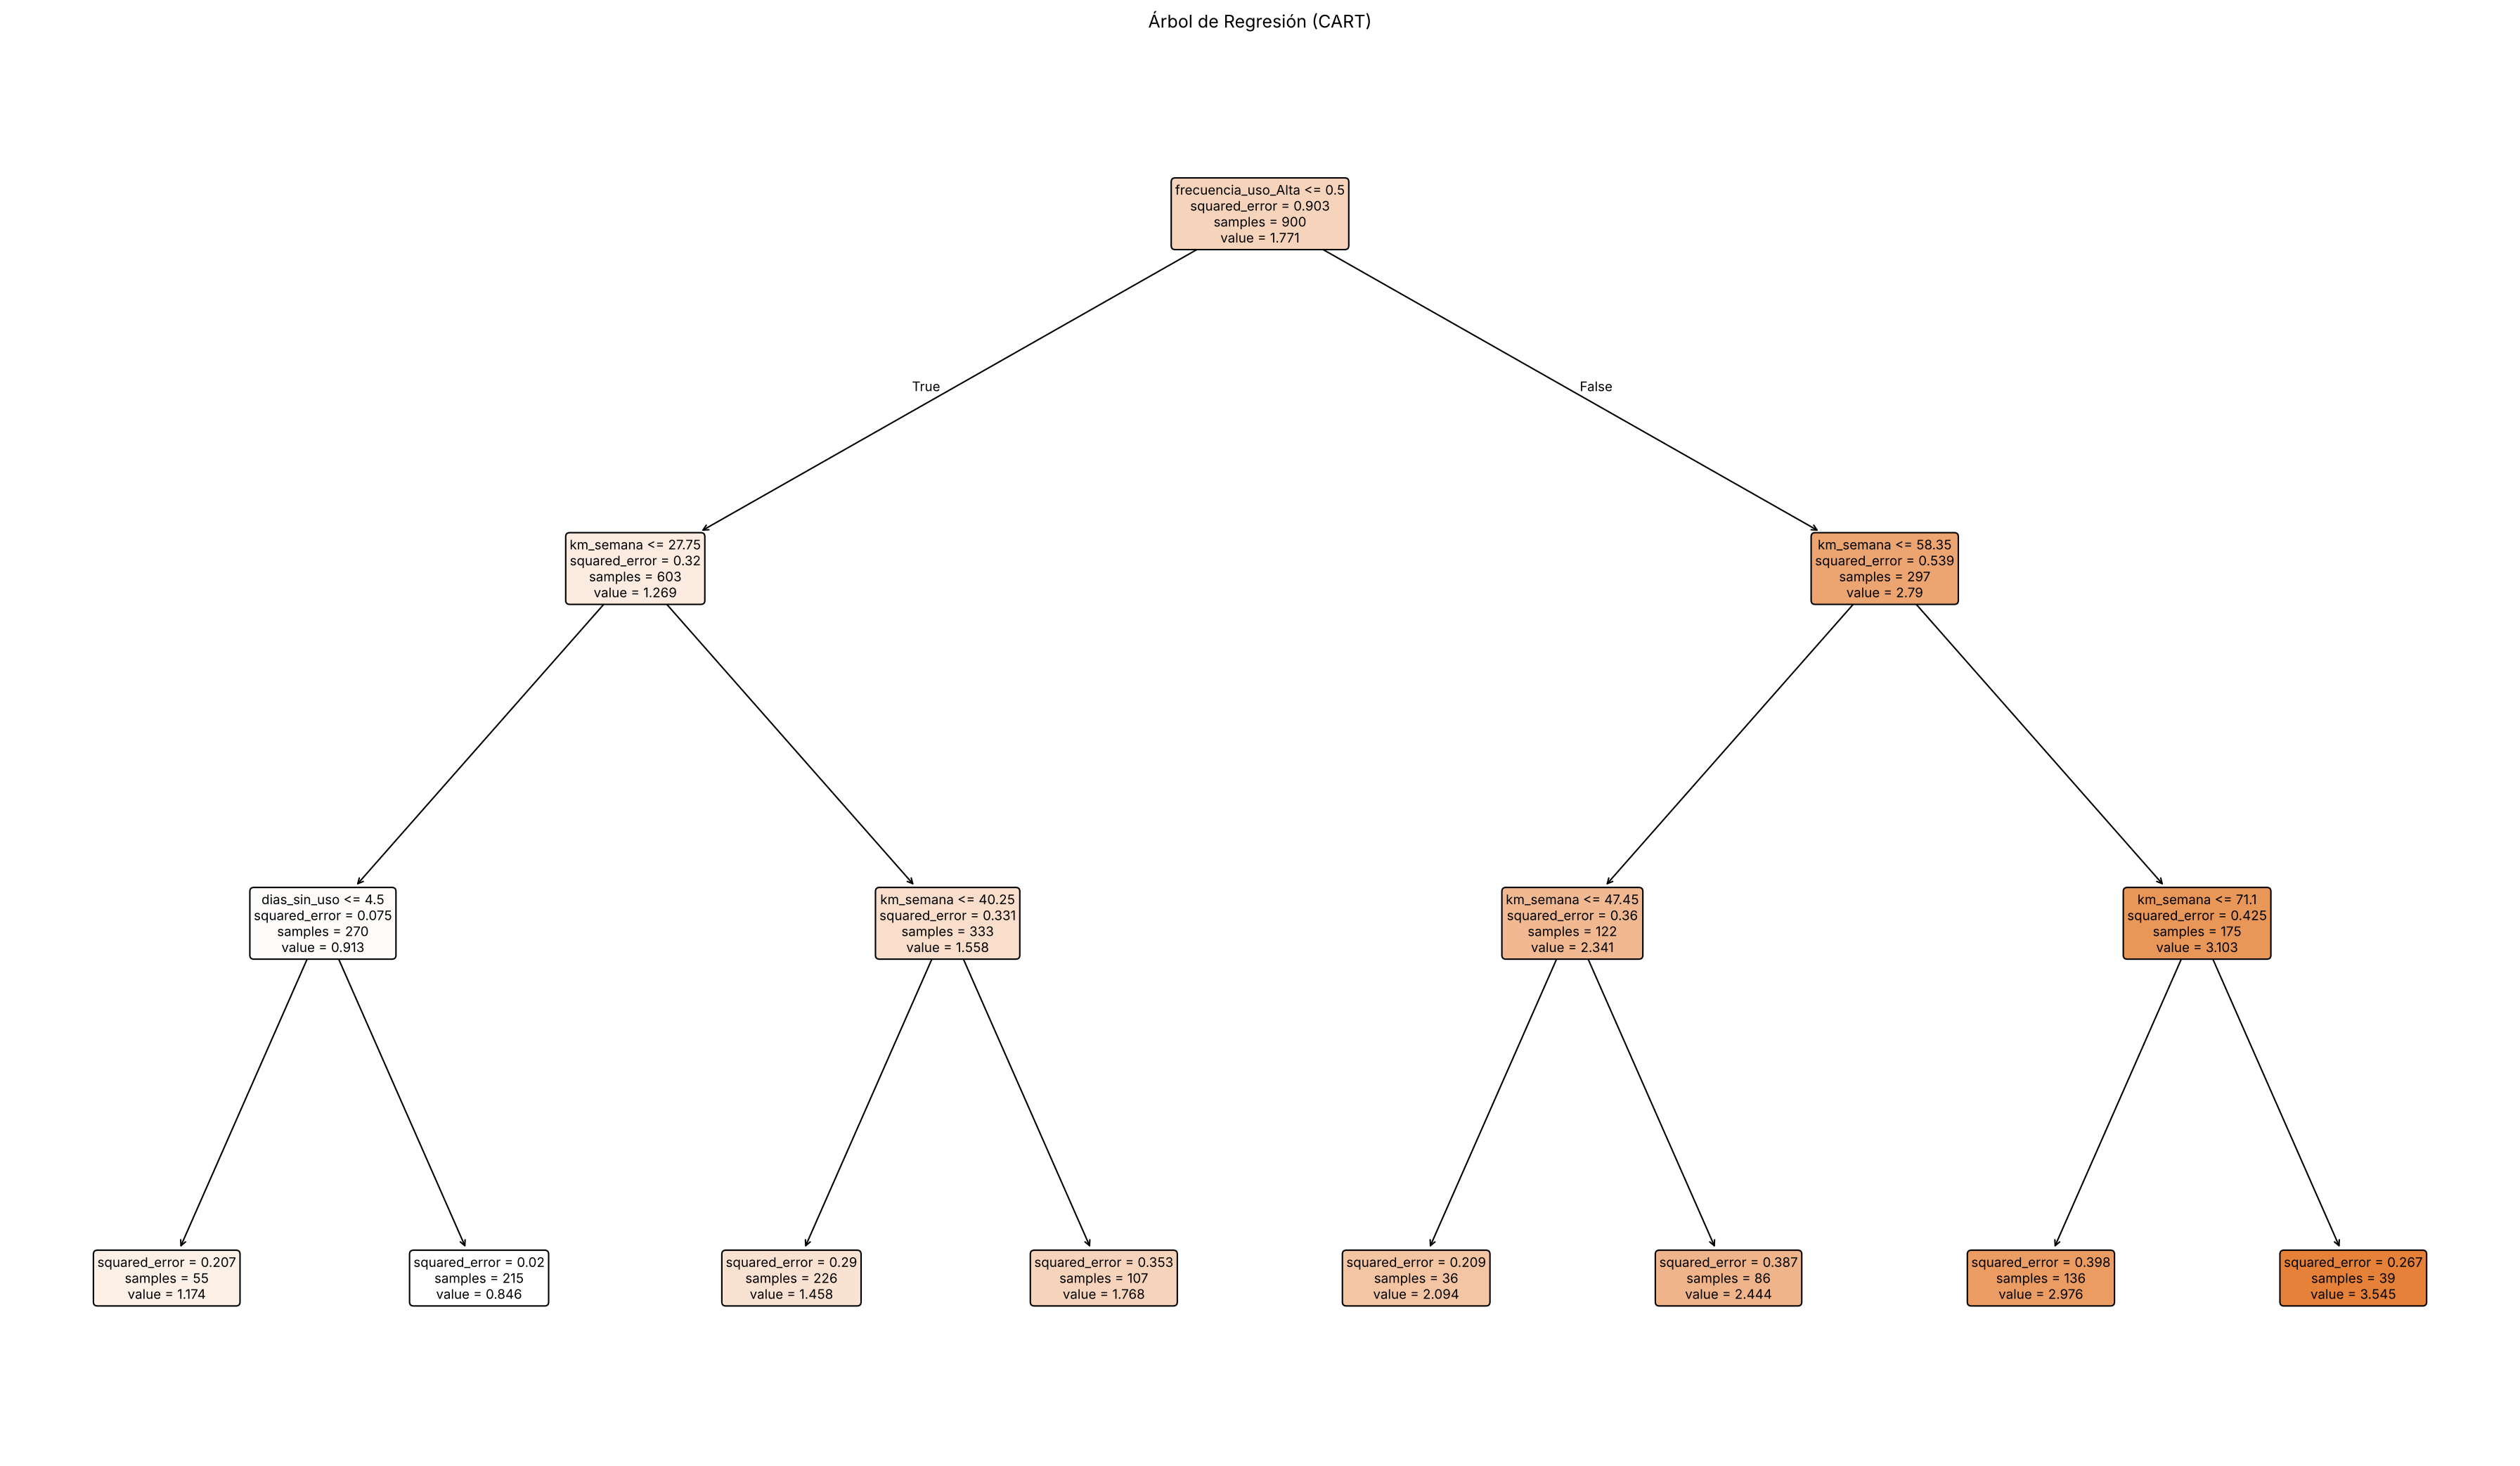

In [27]:
reg = best_reg.named_steps['model']

plt.figure(figsize=(24, 14), dpi=150)
plot_tree(reg, feature_names=feature_names, filled=True, rounded=True, fontsize=9)
plt.title("Árbol de Regresión (CART)")
plt.tight_layout()
plt.show()

Exportamos el árbol a Graphviz para obtener una imagen con un acomodo más limpio de los nodos.

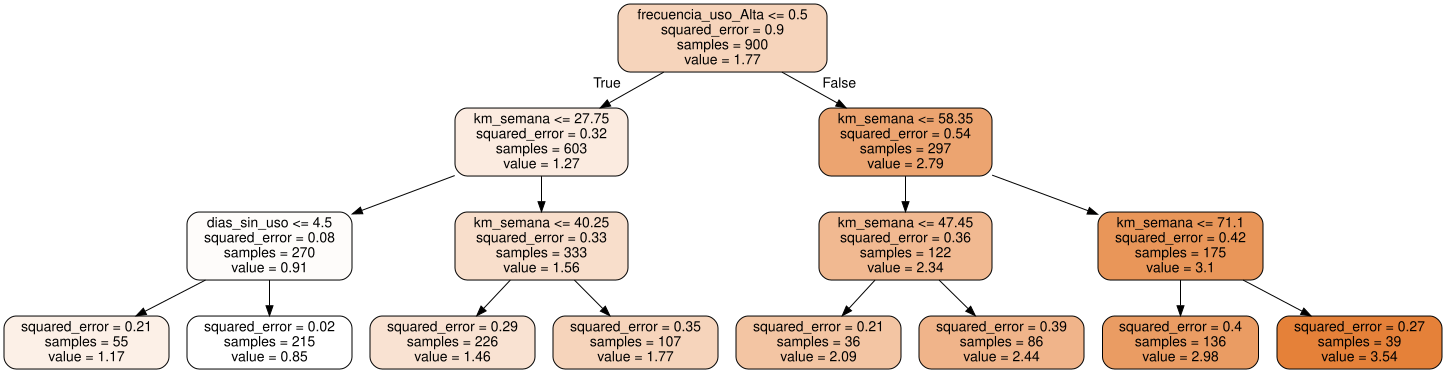

In [28]:
export_graphviz(reg, out_file='arbol_regresion.dot', feature_names=feature_names,
                filled=True, rounded=True, impurity=True, proportion=False, precision=2)

from graphviz import Source
Source.from_file('arbol_regresion.dot')

### Reglas de predicción principales
El **nodo raíz es `frecuencia_uso_Alta`**: separar a los usuarios de uso alto es lo que más reduce el MSE. Después, `km_semana` define los escalones de consumo. Cada hoja muestra el consumo promedio (kWh/semana) de su grupo.

| Perfil (regla) | Consumo estimado |
|---|---|
| Frecuencia no Alta, `km_semana` ≤ 27.8, `dias_sin_uso` > 4.5 | **0.85 kWh** (grupo más grande, usuarios casi inactivos) |
| Frecuencia no Alta, `km_semana` ≤ 27.8, `dias_sin_uso` ≤ 4.5 | 1.17 kWh |
| Frecuencia no Alta, `km_semana` entre 27.8 y 40.3 | 1.46 kWh |
| Frecuencia no Alta, `km_semana` > 40.3 | 1.77 kWh |
| Frecuencia Alta, `km_semana` ≤ 47.5 | 2.09 kWh |
| Frecuencia Alta, `km_semana` entre 47.5 y 58.4 | 2.44 kWh |
| Frecuencia Alta, `km_semana` entre 58.4 y 71.1 | 2.98 kWh |
| Frecuencia Alta, `km_semana` > 71.1 | **3.54 kWh** (usuarios intensivos) |

El consumo crece en escalones según la intensidad de uso. Un usuario intensivo consume **unas 4 veces más** energía por semana que uno casi inactivo.

## 16. Importancia de variables (regresión)

frecuencia_uso_Alta           0.781988
km_semana                     0.210002
dias_sin_uso                  0.008010
frecuencia_uso_Media          0.000000
frecuencia_uso_Baja           0.000000
satisfaccion_general_Alta     0.000000
satisfaccion_general_Baja     0.000000
edad                          0.000000
satisfaccion_general_Media    0.000000
ingresos_mensuales            0.000000
membresia_premium             0.000000
dtype: float64


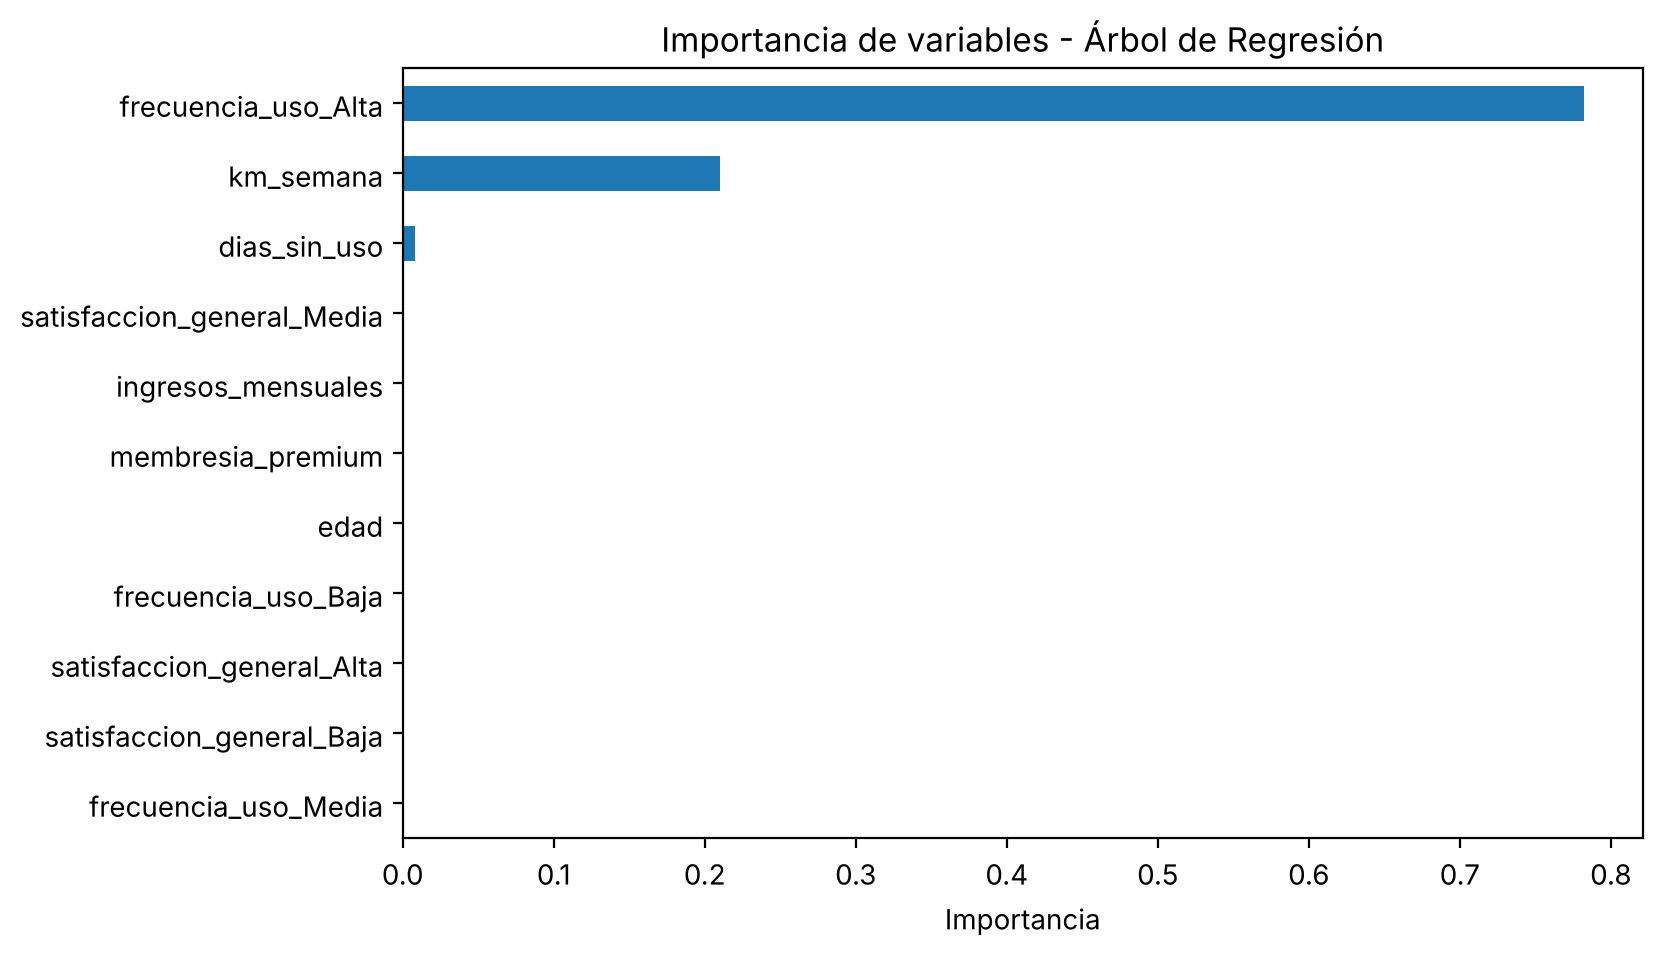

In [29]:
imp_reg = pd.Series(reg.feature_importances_, index=feature_names).sort_values(ascending=False)
print(imp_reg)

imp_reg.sort_values().plot(kind='barh', figsize=(8, 5))
plt.title('Importancia de variables - Árbol de Regresión')
plt.xlabel('Importancia')
plt.show()

### Interpretación de la importancia de variables
- **`frecuencia_uso_Alta` (78 %)** y **`km_semana` (21 %)** explican prácticamente todo el consumo energético. Ambas miden la intensidad de uso.
- **`dias_sin_uso` (1 %)** solo ajusta a los usuarios poco activos.
- Las variables demográficas (`edad`, `ingresos_mensuales`), la satisfacción y la membresía **no aportan** a la predicción del consumo. El consumo depende de **cómo** se usa el servicio, no de **quién** lo usa.

## 17. Selección de profundidad y sobreajuste (regresión)
**Método 1: Validación cruzada** (R² promedio por profundidad).

In [30]:
scores = []
depths = range(1, 16)

for d in depths:
    m = Pipeline([('prep', preprocess),
                  ('model', DecisionTreeRegressor(max_depth=d, random_state=42))])
    scores.append(cross_val_score(m, Xr_train, yr_train, cv=5, scoring='r2').mean())

for d, s in zip(depths, scores):
    print(f"max_depth={d}, R² promedio={s:.4f}")

print("Profundidad óptima (R² CV):", depths[np.argmax(scores)])

max_depth=1, R² promedio=0.5577
max_depth=2, R² promedio=0.6690
max_depth=3, R² promedio=0.6864
max_depth=4, R² promedio=0.6789
max_depth=5, R² promedio=0.6622
max_depth=6, R² promedio=0.6326
max_depth=7, R² promedio=0.5884
max_depth=8, R² promedio=0.5631
max_depth=9, R² promedio=0.5210
max_depth=10, R² promedio=0.5186
max_depth=11, R² promedio=0.4797
max_depth=12, R² promedio=0.4698
max_depth=13, R² promedio=0.4521
max_depth=14, R² promedio=0.4475
max_depth=15, R² promedio=0.4418
Profundidad óptima (R² CV): 3


**Método 2: Curva de validación** (MSE promedio de validación cruzada).

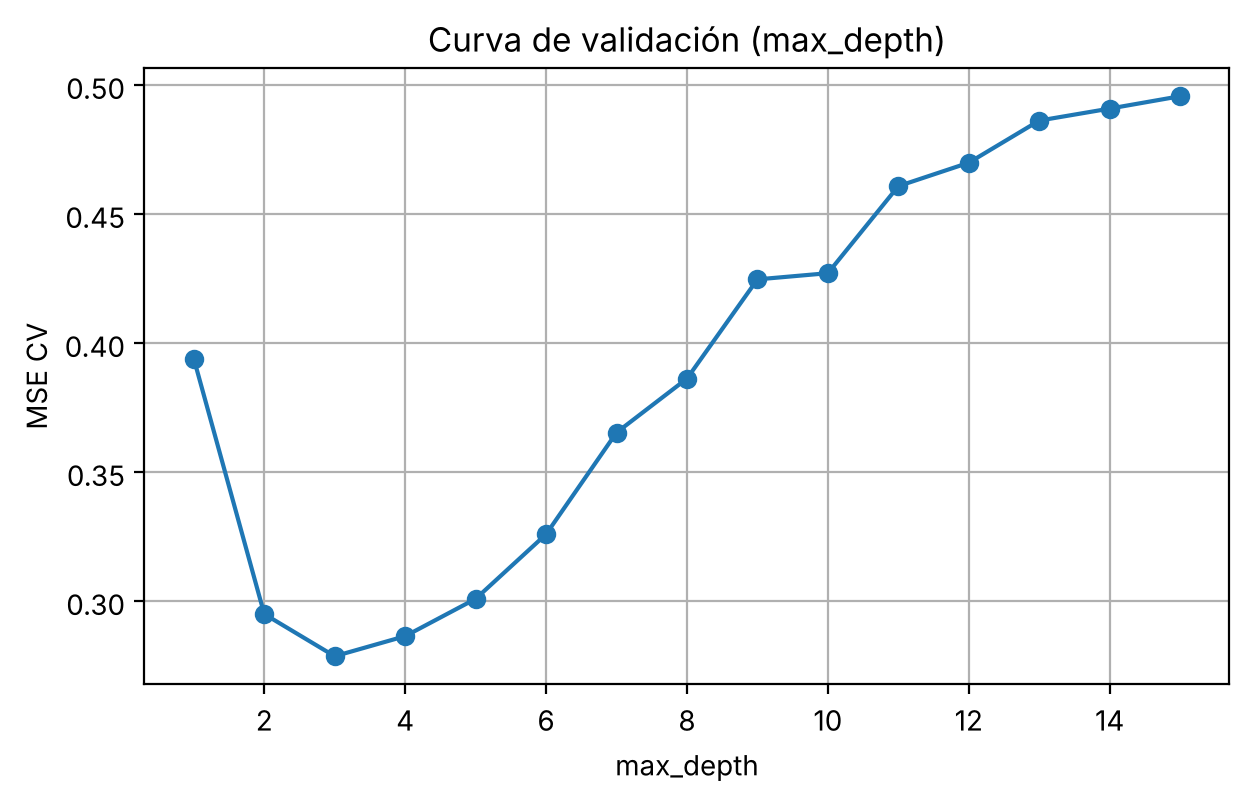

Profundidad óptima aproximada (curva): 3


In [31]:
cv_means = []
for d in depths:
    m = Pipeline([('prep', preprocess),
                  ('model', DecisionTreeRegressor(max_depth=d, random_state=42))])
    cv_means.append(-cross_val_score(m, Xr_train, yr_train, cv=5, scoring='neg_mean_squared_error').mean())

plt.figure(figsize=(7, 4))
plt.plot(depths, cv_means, marker='o')
plt.title('Curva de validación (max_depth)')
plt.xlabel('max_depth')
plt.ylabel('MSE CV')
plt.grid(True)
plt.show()

print('Profundidad óptima aproximada (curva):', depths[int(np.argmin(cv_means))])

**Método 3: Curva de aprendizaje** (error de entrenamiento vs validación cruzada). El conjunto de prueba no se usa para elegir la profundidad.

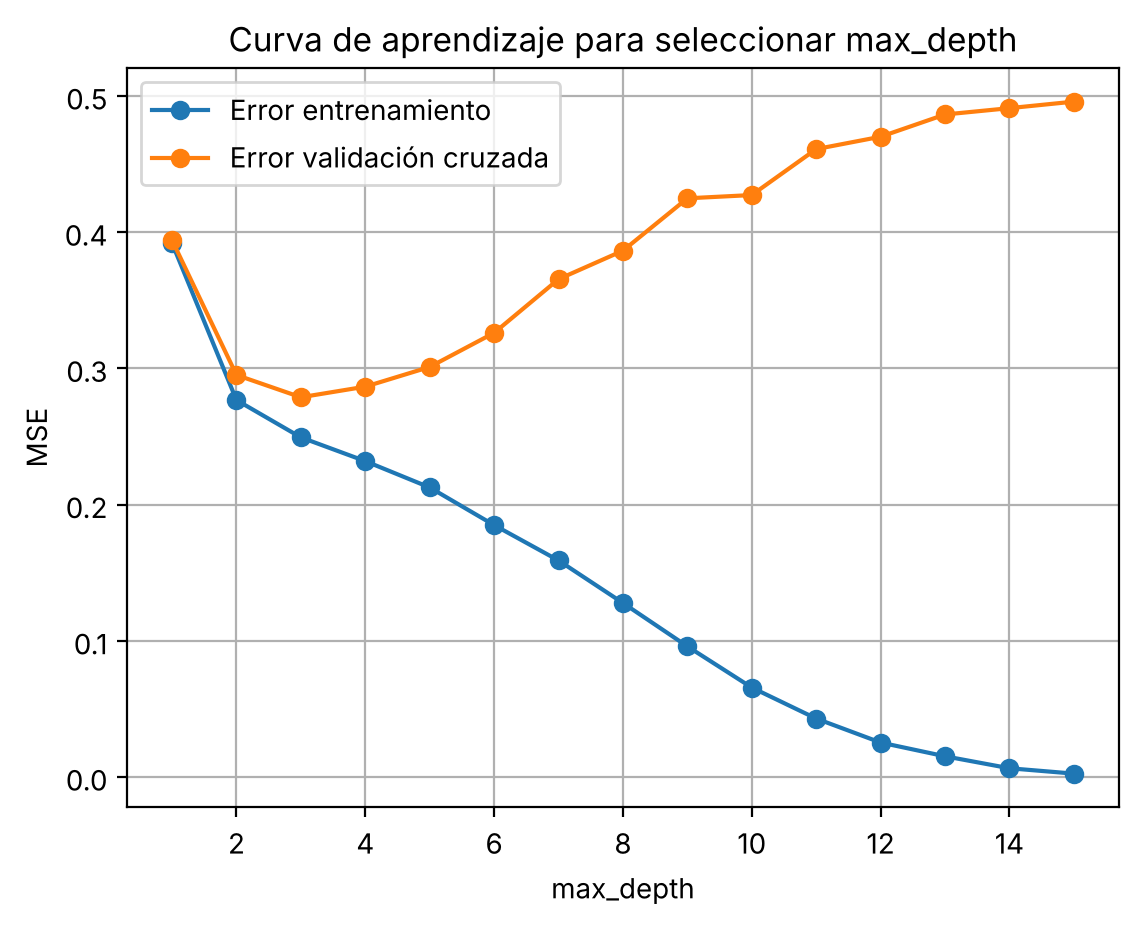

Modelo final -> R² entrenamiento: 0.7241 | R² prueba: 0.6984


In [32]:
train_errors = []

for d in depths:
    m = Pipeline([('prep', preprocess),
                  ('model', DecisionTreeRegressor(max_depth=d, random_state=42))])
    m.fit(Xr_train, yr_train)
    train_errors.append(mean_squared_error(yr_train, m.predict(Xr_train)))

plt.plot(depths, train_errors, label='Error entrenamiento', marker='o')
plt.plot(depths, cv_means, label='Error validación cruzada', marker='o')
plt.xlabel('max_depth')
plt.ylabel('MSE')
plt.legend()
plt.grid(True)
plt.title('Curva de aprendizaje para seleccionar max_depth')
plt.show()

print("Modelo final -> R² entrenamiento:", round(r2_score(yr_train, best_reg.predict(Xr_train)), 4),
      "| R² prueba:", round(r2, 4))

### Interpretación del sobreajuste
- **Los tres métodos coinciden en que la profundidad óptima es 3,** y los tres usan solo los datos de entrenamiento:
  - R² de validación cruzada máximo de 0.686.
  - MSE de validación cruzada mínimo (0.279).
  - La brecha entre el error de entrenamiento y el de validación cruzada empieza a crecer después de 3 niveles.
- **A mayor profundidad:**
  - El MSE de entrenamiento cae casi a 0, porque el árbol memoriza los datos.
  - El MSE de validación cruzada sube de 0.279 a 0.496.
  
  Es un **sobreajuste** claro.
- **Modelo final:** R² de 0.72 en entrenamiento y 0.70 en prueba. La brecha es mínima, así que el modelo **generaliza bien** a usuarios nuevos.

---
## 18. Simulación de usuarios nuevos
Aplicamos los modelos finales a cuatro perfiles hipotéticos de usuario para mostrar cómo se usarían en la operación.

In [33]:
nuevos = pd.DataFrame({
    'edad': [30, 35, 40, 28],
    'ingresos_mensuales': [18000, 20000, 12000, 15000],
    'km_semana': [60, 50, 15, 80],
    'frecuencia_uso': ['Alta', 'Media', 'Baja', 'Alta'],
    'satisfaccion_general': ['Alta', 'Media', 'Baja', 'Media'],
    'membresia_premium': [1, 1, 0, 0],
    'dias_sin_uso': [1, 2, 7, 1]
}, index=['Promotor', 'Premium poco satisfecho', 'Básico inactivo', 'Intensivo sin premium'])

nuevos['prob_recomienda'] = best_clf.predict_proba(nuevos[X.columns])[:, 1].round(3)
nuevos['recomienda_original'] = best_clf.predict(nuevos[X.columns])
nuevos['recomienda_balanceado'] = best_bal.predict(nuevos[X.columns])
nuevos['consumo_kwh_estimado'] = best_reg.predict(nuevos[X.columns]).round(2)
nuevos

,edad,ingresos_mensuales,km_semana,frecuencia_uso,satisfaccion_general,membresia_premium,dias_sin_uso,prob_recomienda,recomienda_original,recomienda_balanceado,consumo_kwh_estimado
Promotor,30,18000,60,Alta,Alta,1,1,0.925,1,1,2.98
Premium poco satisfecho,35,20000,50,Media,Media,1,2,0.549,1,1,1.77
Básico inactivo,40,12000,15,Baja,Baja,0,7,0.056,0,0,0.85
Intensivo sin premium,28,15000,80,Alta,Media,0,1,0.312,0,1,3.54


**Interpretación:** los perfiles son hipotéticos y sirven para ilustrar el uso de los modelos.
- El **promotor** tiene 92.5 % de probabilidad de recomendar y un consumo estimado de 2.98 kWh.
- El **básico inactivo** tiene solo 5.6 % de probabilidad de recomendar y consume 0.85 kWh.
- El **intensivo sin premium** muestra la diferencia entre modelos. Su probabilidad de recomendar es de 31.2 %: el modelo original lo clasifica como "No recomienda" y el balanceado como "Recomienda". Además, es el perfil con el consumo más alto (3.54 kWh).